In [1]:
# Importation des bibliothèques nécessaires
import os
import glob
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

Department 61: 23 stations - 3,383,059 records merged.
Department 69: 25 stations - 3,626,842 records merged.


,AAAAMMJJHH,T,station_id
0,1990-01-01 00:00:00,-1.4,61001001
1,1990-01-01 01:00:00,-1.5,61001001
2,1990-01-01 02:00:00,-1.7,61001001
3,1990-01-01 03:00:00,-1.8,61001001
4,1990-01-01 04:00:00,-1.7,61001001


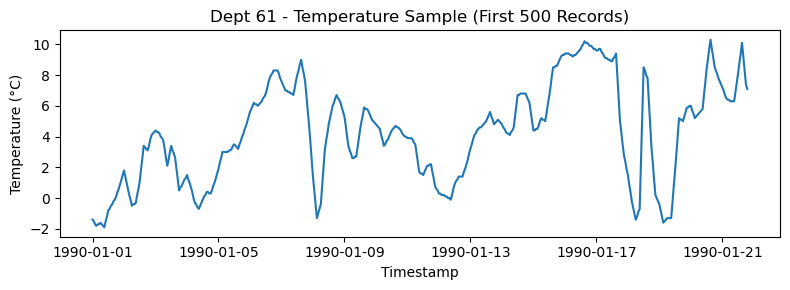

,AAAAMMJJHH,T,station_id
0,1990-01-01 00:00:00,-3.9,69299001
1,1990-01-01 00:00:00,-2.9,69029001
2,1990-01-01 01:00:00,-4.0,69299001
3,1990-01-01 01:00:00,-3.1,69029001
4,1990-01-01 02:00:00,-4.2,69299001


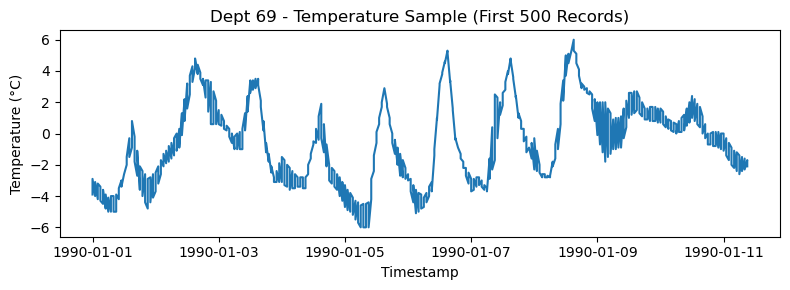

In [2]:
# Chargement des données brutes pour chaque département et aperçu rapide des températures
def load_department_data(dept: int) -> pd.DataFrame:
    # Recherche des fichiers CSV d'un département
    pattern = f"DEPT_{dept}/DEPT_{dept}_STATION_*.csv"
    files = sorted(glob.glob(pattern))
    if not files:
        raise FileNotFoundError(f"No CSV files found for department {dept}.")

    frames = []
    for f in files:
        try:
            # Lecture du fichier station
            df = pd.read_csv(f, sep=";", parse_dates=["AAAAMMJJHH"], encoding="utf-8")

            # Vérification : température disponible
            if "T" not in df.columns:
                continue

            # Extraction de l'identifiant de station depuis le nom du fichier
            station_id = os.path.basename(f).split("_STATION_")[1].split(".")[0]
            df["station_id"] = station_id

            # Sélection des colonnes utiles
            frames.append(df[["AAAAMMJJHH", "T", "station_id"]])
        except Exception as e:
            print(f"Error loading {f}: {e}")

    # Fusion de toutes les stations du département
    data = pd.concat(frames, ignore_index=True)

    # Nettoyage et tri chronologique
    data = data.dropna(subset=["AAAAMMJJHH", "T"]).sort_values("AAAAMMJJHH").reset_index(drop=True)

    # Affichage du nombre de stations et d'enregistrements
    station_count = data["station_id"].nunique()
    print(f"Department {dept}: {station_count} stations - {len(data):,} records merged.")
    return data


# Départements sélectionnés
DEPARTMENTS = [61, 69]

# Chargement des données de chaque département
dept_data = {dept: load_department_data(dept) for dept in DEPARTMENTS}

for dept in DEPARTMENTS:
    df = dept_data[dept]
    display(df.head())  # Aperçu des premières lignes du dataset

    # Visualisation d'un échantillon de températures
    plt.figure(figsize=(8, 3))
    plt.plot(df["AAAAMMJJHH"].iloc[:500], df["T"].iloc[:500])
    plt.title(f"Dept {dept} - Temperature Sample (First 500 Records)")
    plt.xlabel("Timestamp")
    plt.ylabel("Temperature (°C)")
    plt.tight_layout()
    plt.show()

Department 61: 3,382,507 rows after feature engineering.
Department 69: 3,626,242 rows after feature engineering.


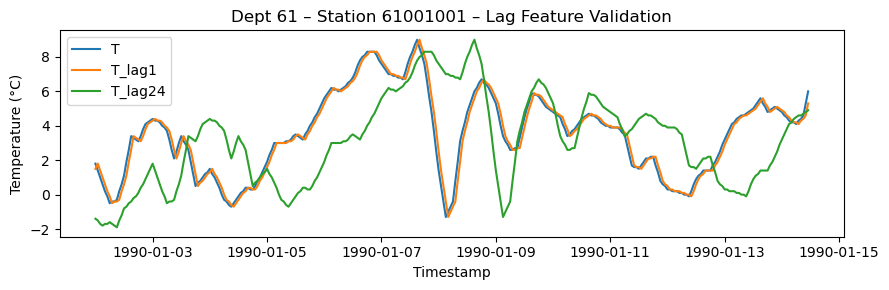

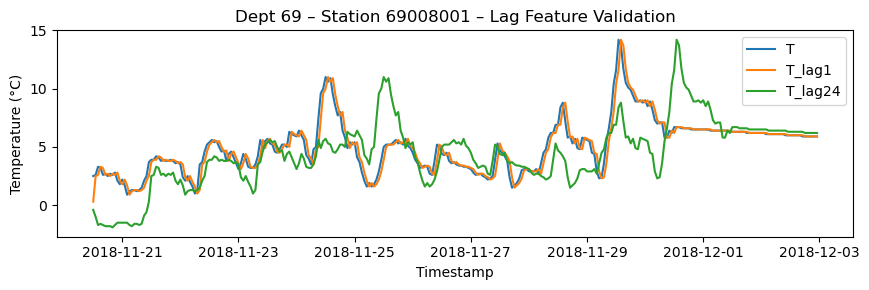

In [3]:
# Création des features temporelles et des décalages (lags) pour enrichir les données
def add_time_features(df):
    # Extraction des composantes temporelles
    ts = pd.to_datetime(df["AAAAMMJJHH"])
    df["hour"] = ts.dt.hour          
    df["day"] = ts.dt.day            
    df["month"] = ts.dt.month        
    df["weekday"] = ts.dt.weekday    

    # Encodage cyclique des heures 
    df["sin_hour"] = np.sin(2 * np.pi * df["hour"] / 24)
    df["cos_hour"] = np.cos(2 * np.pi * df["hour"] / 24)

    return df


def add_lag_features(df):
    # Tri par station puis par date
    df = df.sort_values(["station_id", "AAAAMMJJHH"], ascending=True)

    # Décalage de 1 heure et 24 heures
    df["T_lag1"] = df.groupby("station_id")["T"].shift(1)
    df["T_lag24"] = df.groupby("station_id")["T"].shift(24)

    # Moyenne glissante sur 24 heures
    df["T_rollmean_24"] = df.groupby("station_id")["T"].transform(
        lambda x: x.rolling(window=24, min_periods=1).mean()
    )

    # Suppression des lignes sans valeurs de lag
    df = df.dropna(subset=["T_lag1", "T_lag24", "T_rollmean_24"])
    return df.reset_index(drop=True)


# Application des features pour chaque département
dept_fe = {}
for dept, df in dept_data.items():
    fe = add_time_features(df.copy())  # Ajout des features temporelles
    fe = add_lag_features(fe)          # Ajout des lags
    dept_fe[dept] = fe
    print(f"Department {dept}: {fe.shape[0]:,} rows after feature engineering.")


# Vérification visuelle des features lag
for dept in DEPARTMENTS:
    stations = dept_fe[dept]["station_id"].unique()
    first_station = stations[0]  

    df_sample = dept_fe[dept][dept_fe[dept]["station_id"] == first_station].iloc[:300]

    plt.figure(figsize=(9, 3))
    plt.plot(df_sample["AAAAMMJJHH"], df_sample["T"], label="T")
    plt.plot(df_sample["AAAAMMJJHH"], df_sample["T_lag1"], label="T_lag1")
    plt.plot(df_sample["AAAAMMJJHH"], df_sample["T_lag24"], label="T_lag24")
    plt.title(f"Dept {dept} – Station {first_station} – Lag Feature Validation")
    plt.xlabel("Timestamp")
    plt.ylabel("Temperature (°C)")
    plt.legend()
    plt.tight_layout()
    plt.show()


Department 61
Split timestamp: 2021-06-15 05:00:00
Train size: 2,705,999 | Test size: 676,508
Train period: 1990-01-02 00:00:00 → 2021-06-15 04:00:00
Test period:  2021-06-15 05:00:00 → 2025-10-12 03:00:00


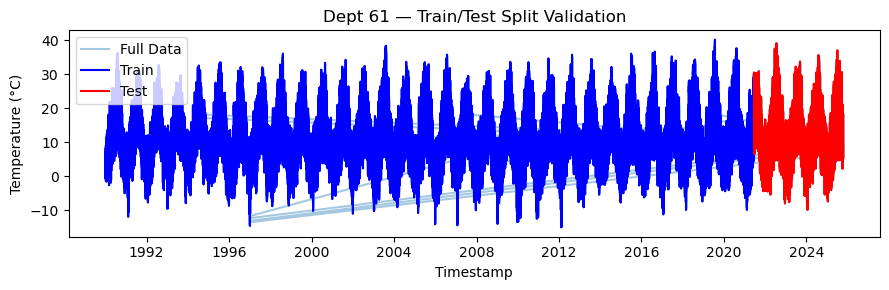


Department 69
Split timestamp: 2021-02-09 18:00:00
Train size: 2,900,984 | Test size: 725,258
Train period: 1990-01-02 00:00:00 → 2021-02-09 17:00:00
Test period:  2021-02-09 18:00:00 → 2025-10-12 03:00:00


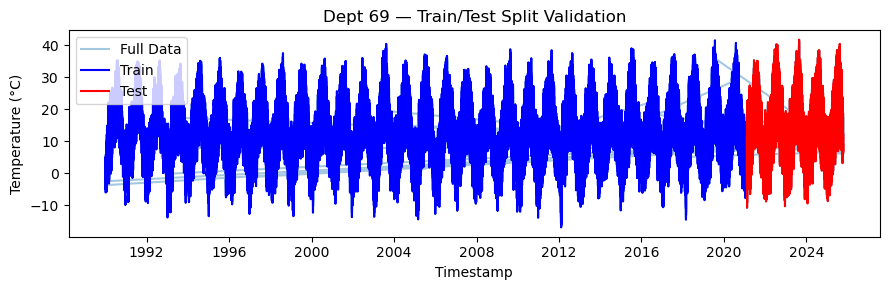

In [4]:
# Séparation temporelle globale (80/20) et visualisation du découpage train/test
warnings.filterwarnings("ignore")

def time_series_split(df, train_ratio=0.8):
    # Tri chronologique du dataset
    df = df.sort_values("AAAAMMJJHH").reset_index(drop=True)

    # Calcul du point de coupure temporel
    split_idx = int(len(df) * train_ratio)
    split_time = df["AAAAMMJJHH"].iloc[split_idx]

    # Découpage global (pas par station)
    train_df = df[df["AAAAMMJJHH"] < split_time].copy()
    test_df = df[df["AAAAMMJJHH"] >= split_time].copy()

    # Séparation features / cible
    feature_cols = [c for c in df.columns if c not in ["AAAAMMJJHH", "T"]]
    X_train, y_train = train_df[feature_cols], train_df["T"]
    X_test, y_test = test_df[feature_cols], test_df["T"]

    # Informations sur les périodes
    print(f"Split timestamp: {split_time}")
    print(f"Train size: {len(X_train):,} | Test size: {len(X_test):,}")
    print(f"Train period: {train_df['AAAAMMJJHH'].min()} → {train_df['AAAAMMJJHH'].max()}")
    print(f"Test period:  {test_df['AAAAMMJJHH'].min()} → {test_df['AAAAMMJJHH'].max()}")

    return X_train, X_test, y_train, y_test, train_df, test_df


# Application de la séparation temporelle pour chaque département
splits = {}
for dept, df in dept_fe.items():
    print(f"\nDepartment {dept}")
    X_train, X_test, y_train, y_test, train_df, test_df = time_series_split(df)

    # Stockage des datasets split
    splits[dept] = {
        "X_train": X_train, 
        "X_test": X_test,
        "y_train": y_train, 
        "y_test": y_test,
        "train_df": train_df,
        "test_df": test_df
    }

    # Visualisation du découpage train/test
    plt.figure(figsize=(9, 3))
    plt.plot(df["AAAAMMJJHH"], df["T"], label="Full Data", alpha=0.4)   
    plt.plot(train_df["AAAAMMJJHH"], train_df["T"], label="Train", color="blue")  
    plt.plot(test_df["AAAAMMJJHH"], test_df["T"], label="Test", color="red")      
    plt.title(f"Dept {dept} — Train/Test Split Validation")
    plt.xlabel("Timestamp")
    plt.ylabel("Temperature (°C)")
    plt.legend()
    plt.tight_layout()
    plt.show()


Department 61
Linear Regression: MSE=0.7931, R2=0.9826
Random Forest    : MSE=0.6152, R2=0.9865


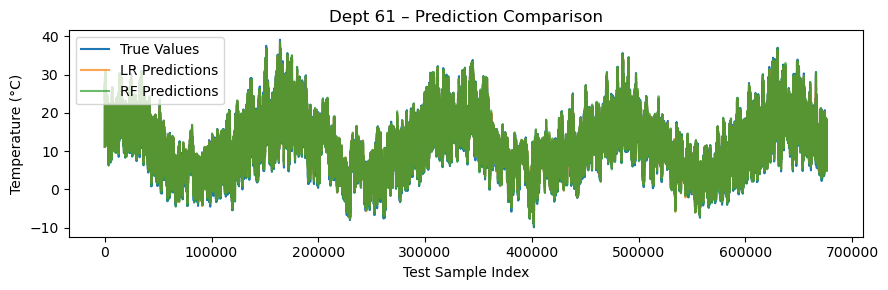


Department 69
Linear Regression: MSE=1.0084, R2=0.9849
Random Forest    : MSE=0.8291, R2=0.9876


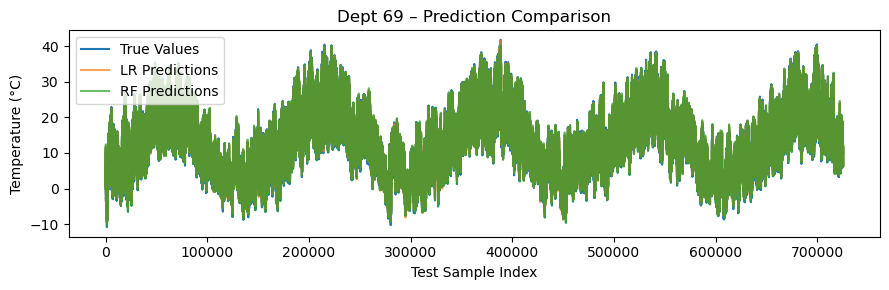

Global model training completed successfully.


In [5]:
# Entraînement des modèles globaux (LR et RF) et comparaison des prédictions sur le test
results = {}

for dept, split in splits.items():
    print(f"\nDepartment {dept}")

    # Récupération du train/test
    X_train, X_test = split["X_train"], split["X_test"]
    y_train, y_test = split["y_train"], split["y_test"]

    # Standardisation des variables numériques
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train.select_dtypes(include=[np.number]))
    X_test_scaled = scaler.transform(X_test.select_dtypes(include=[np.number]))

    # Modèle global : Régression Linéaire
    lr_model = LinearRegression()
    lr_model.fit(X_train_scaled, y_train)
    y_pred_lr = lr_model.predict(X_test_scaled)
    mse_lr = mean_squared_error(y_test, y_pred_lr)
    r2_lr = r2_score(y_test, y_pred_lr)

    # Modèle global : Random Forest
    rf_model = RandomForestRegressor(
        n_estimators=150,
        max_depth=12,
        min_samples_leaf=3,
        random_state=58,
        n_jobs=-1
    )
    rf_model.fit(X_train_scaled, y_train)
    y_pred_rf = rf_model.predict(X_test_scaled)
    mse_rf = mean_squared_error(y_test, y_pred_rf)
    r2_rf = r2_score(y_test, y_pred_rf)

    # Stockage des résultats pour le département
    results[dept] = {
        "lr_model": lr_model,
        "rf_model": rf_model,
        "scaler": scaler,
        "X_test": X_test,
        "y_test": y_test,
        "y_pred_lr": y_pred_lr,
        "y_pred_rf": y_pred_rf,
        "mse_lr": mse_lr,
        "r2_lr": r2_lr,
        "mse_rf": mse_rf,
        "r2_rf": r2_rf
    }

    # Affichage des métriques globales
    print(f"Linear Regression: MSE={mse_lr:.4f}, R2={r2_lr:.4f}")
    print(f"Random Forest    : MSE={mse_rf:.4f}, R2={r2_rf:.4f}")

    # Visualisation des prédictions globales
    plt.figure(figsize=(9, 3))
    plt.plot(y_test.values, label="True Values", linewidth=1.5)   
    plt.plot(y_pred_lr, label="LR Predictions", alpha=0.7)        
    plt.plot(y_pred_rf, label="RF Predictions", alpha=0.7)        
    plt.title(f"Dept {dept} – Prediction Comparison")
    plt.xlabel("Test Sample Index")
    plt.ylabel("Temperature (°C)")
    plt.legend()
    plt.tight_layout()
    plt.show()

print("Global model training completed successfully.")

In [6]:
# Évaluation du modèle global station-par-station et comparaison avec les résultats locaux (TP02)
warnings.filterwarnings("ignore", message="X does not have valid feature names")


def evaluate_global_model_per_station(model, scaler, test_df, num_cols, all_stations, target_col="T"):
    # Évalue le modèle global pour chaque station (MSE & R²)
    results = []
    for st in all_stations:

        # Sélection des données test pour une station
        st_df = test_df[test_df["station_id"] == st].copy()

        # Si la station n'a pas de données test
        if st_df.empty:
            results.append({
                "station_id": str(st).strip(),
                "mse": np.nan,
                "r2": np.nan
            })
            continue

        # Données d'entrée pour la station
        X_st = st_df[num_cols]
        X_st_scaled = scaler.transform(X_st)
        y_st = st_df[target_col].values

        # Prédiction du modèle global
        y_pred = model.predict(X_st_scaled)

        # Stockage des performances
        results.append({
            "station_id": str(st).strip(),
            "mse": mean_squared_error(y_st, y_pred),
            "r2": r2_score(y_st, y_pred)
        })

    return pd.DataFrame(results)


# Traitement pour chaque département
for dept, res in results.items():
    print(f"\nDepartment {dept}")

    # Sauvegarde des modèles globaux LR & RF
    lr_path = f"DEPT_{dept}_GLOBAL_LR.pkl"
    rf_path = f"DEPT_{dept}_GLOBAL_RF.pkl"
    joblib.dump(res["lr_model"], lr_path)
    joblib.dump(res["rf_model"], rf_path)
    print(f"Saved models: {lr_path}, {rf_path}")

    # Préparation du test avec station_id et T
    X_test = res["X_test"].copy()
    y_test = res["y_test"].copy()
    X_test["T"] = y_test
    X_test["station_id"] = X_test["station_id"].astype(str).str.strip()
    scaler = res["scaler"]

    # Colonnes numériques uniquement pour les modèles
    drop_cols = [c for c in ["AAAAMMJJHH", "T", "station_id"] if c in X_test.columns]
    num_cols = X_test.drop(columns=drop_cols).select_dtypes(include=[np.number]).columns.tolist()

    # Liste de toutes les stations du département
    all_stations = dept_fe[dept]["station_id"].astype(str).str.strip().unique()

    # Évaluation du modèle global LR & RF
    df_lr = evaluate_global_model_per_station(res["lr_model"], scaler, X_test, num_cols, all_stations)
    df_rf = evaluate_global_model_per_station(res["rf_model"], scaler, X_test, num_cols, all_stations)

    # Fusion des résultats LR et RF
    merged_global = pd.merge(
        df_lr.rename(columns={"mse": "mse_lr_global", "r2": "r2_lr_global"}),
        df_rf.rename(columns={"mse": "mse_rf_global", "r2": "r2_rf_global"}),
        on="station_id"
    )

    # Tri par numéro de station
    merged_global["__num"] = pd.to_numeric(
        merged_global["station_id"].str.extract(r"(\d+)", expand=False),
        errors="coerce"
    )
    merged_global = merged_global.sort_values(by=["__num", "station_id"], kind="mergesort") \
                                 .drop(columns="__num") \
                                 .reset_index(drop=True)

    # Sauvegarde du fichier global station-par-station
    file_global = f"results_per_station_global_model_DEPT_{dept}.csv"
    merged_global.to_csv(file_global, index=False)
    print(f"Saved global per-station metrics: {file_global}")

    # Recherche du fichier TP02
    tp02= [
        f"local_results_DEPT_{dept}_TP02.csv"
    ]
    tp02_path = next((p for p in tp02 if os.path.exists(p)), None)

    if not tp02_path:
        print(f"No TP02 comparison file found for Department {dept}. Skipping comparison.")
        continue

    # Chargement du fichier local TP02
    local = pd.read_csv(tp02_path)
    local = local.rename(columns={
        "mse_lr": "mse_lr_local",
        "r2_lr": "r2_lr_local",
        "mse_rf": "mse_rf_local",
        "r2_rf": "r2_rf_local"
    })

    # Nettoyage des IDs pour correspondance
    local["station_id"] = local["station_id"].astype(str).str.extract(r"(\d+)")[0].str.strip()
    merged_global["station_id"] = merged_global["station_id"].astype(str).str.extract(r"(\d+)")[0].str.strip()

    # Fusion local vs global
    merged = pd.merge(local, merged_global, on="station_id", how="outer")

    # Calcul des différences Local - Global
    merged["ΔMSE_LR"] = merged["mse_lr_local"] - merged["mse_lr_global"]
    merged["ΔR2_LR"] = merged["r2_lr_local"] - merged["r2_lr_global"]
    merged["ΔMSE_RF"] = merged["mse_rf_local"] - merged["mse_rf_global"]
    merged["ΔR2_RF"] = merged["r2_rf_local"] - merged["r2_rf_global"]

    # Suppression éventuelle d’une colonne inutile
    merged.drop(columns=[c for c in merged.columns if c.lower() == "department"],
                inplace=True, errors="ignore")

    # Ordre des colonnes dans le tableau
    col_order = [
        "mse_lr_local", "mse_lr_global", "ΔMSE_LR",
        "r2_lr_local", "r2_lr_global", "ΔR2_LR",
        "mse_rf_local", "mse_rf_global", "ΔMSE_RF",
        "r2_rf_local", "r2_rf_global", "ΔR2_RF"
    ]
    existing_cols = [c for c in col_order if c in merged.columns]
    merged = merged[["station_id"] + existing_cols]

    # Tri par numéro de station
    merged["__num"] = pd.to_numeric(
        merged["station_id"].str.extract(r"(\d+)", expand=False),
        errors="coerce"
    )
    merged = merged.sort_values(by=["__num", "station_id"], kind="mergesort") \
                   .drop(columns="__num") \
                   .reset_index(drop=True)

    # Sauvegarde du fichier comparatif TP02 vs TP03
    file_comp = f"results_DEPT_{dept}_TP02_vs_TP03.csv"
    merged.to_csv(file_comp, index=False)
    print(f"Saved TP02 vs TP03 comparison: {file_comp}")

print("\nAll global models saved and per-station comparisons completed.")


Department 61
Saved models: DEPT_61_GLOBAL_LR.pkl, DEPT_61_GLOBAL_RF.pkl
Saved global per-station metrics: results_per_station_global_model_DEPT_61.csv
Saved TP02 vs TP03 comparison: results_DEPT_61_TP02_vs_TP03.csv

Department 69
Saved models: DEPT_69_GLOBAL_LR.pkl, DEPT_69_GLOBAL_RF.pkl
Saved global per-station metrics: results_per_station_global_model_DEPT_69.csv
Saved TP02 vs TP03 comparison: results_DEPT_69_TP02_vs_TP03.csv

All global models saved and per-station comparisons completed.


In [7]:
# Préparation des outils pour extraire les données d’une station et appliquer le scaler global
dept_list = sorted(results.keys())
dept = dept_list[0]

# Liste triée des stations du département
all_stations = sorted(
    dept_fe[dept]["station_id"].astype(str).str.strip().unique(),
    key=lambda x: (pd.to_numeric(''.join(filter(str.isdigit, x)), errors='coerce'), x)
)

def get_num_cols(res_df, include_cols):
    # Retourne uniquement les colonnes numériques utilisées par le modèle
    drop_cols = [c for c in include_cols if c in res_df.columns]
    return res_df.drop(columns=drop_cols).select_dtypes(include=[np.number]).columns.tolist()

def get_subset_scaled(dept, st, res):
    # Extraction de toutes les observations d'une station donnée
    df_full = dept_fe[dept]
    subset = df_full[df_full["station_id"] == st].copy().sort_values("AAAAMMJJHH")

    # Sélection des colonnes numériques cohérentes avec X_test
    num_cols = get_num_cols(res["X_test"], ["AAAAMMJJHH", "T", "station_id"])

    # Transformation avec le scaler global
    X_scaled = res["scaler"].transform(subset[num_cols])

    # Valeurs réelles de température
    y_true = subset["T"].values

    return subset, num_cols, X_scaled, y_true

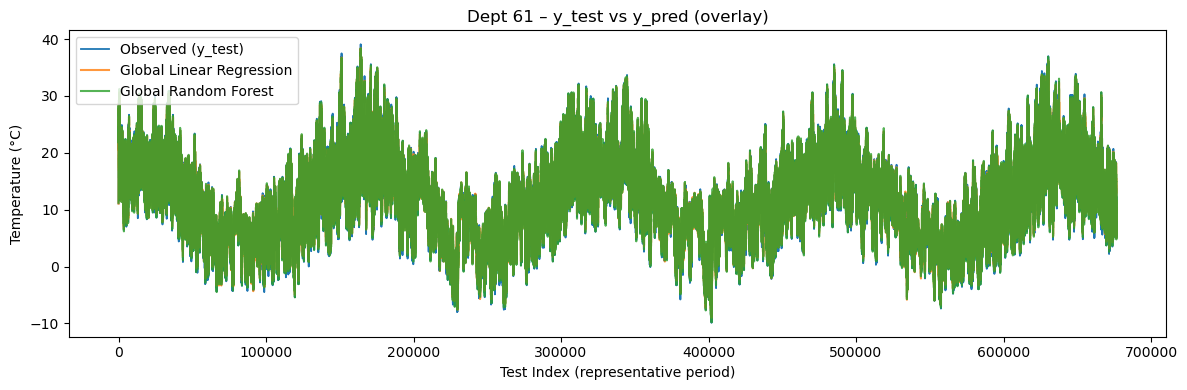

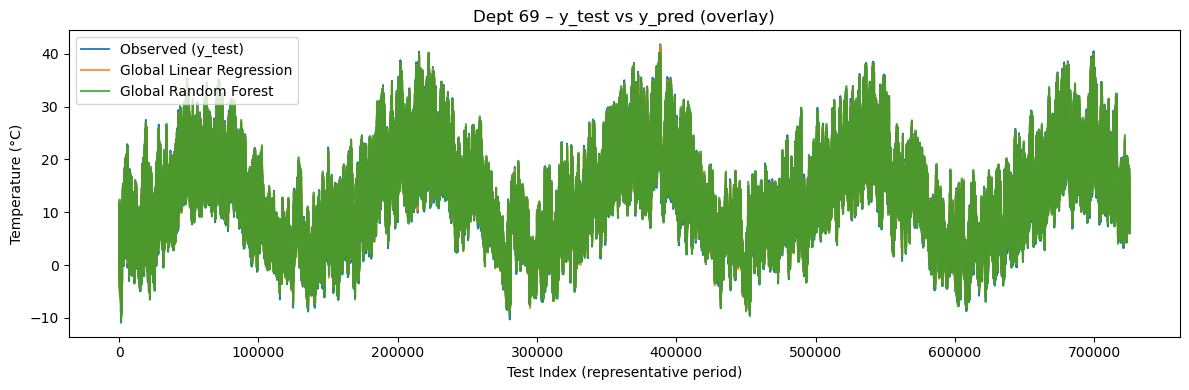

In [8]:
# Courbe y_test vs y_pred (overlay) pour une période représentative
for d in dept_list:
    res = results[d]

    # y_test = valeurs réelles du jeu de test global
    y_test = res["y_test"]

    # y_pred_lr = prédictions du modèle global LR
    y_pred_lr = res["y_pred_lr"]

    # y_pred_rf = prédictions du modèle global RF
    y_pred_rf = res["y_pred_rf"]
    
    # Trace : y_test vs prédictions globales
    plt.figure(figsize=(12, 4))

    # Valeurs réelles
    plt.plot(y_test.values, label="Observed (y_test)", linewidth=1.3)

    # Prédictions du modèle global LR
    plt.plot(y_pred_lr, label="Global Linear Regression", alpha=0.8)

    # Prédictions du modèle global RF
    plt.plot(y_pred_rf, label="Global Random Forest", alpha=0.8)

    # Titre et axes
    plt.title(f"Dept {d} – y_test vs y_pred (overlay)")
    plt.xlabel("Test Index (representative period)")
    plt.ylabel("Temperature (°C)")
    plt.legend()
    plt.tight_layout()
    plt.show()

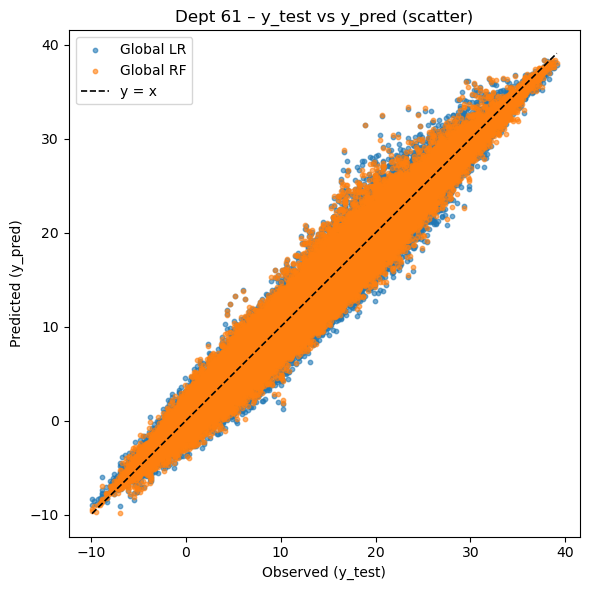

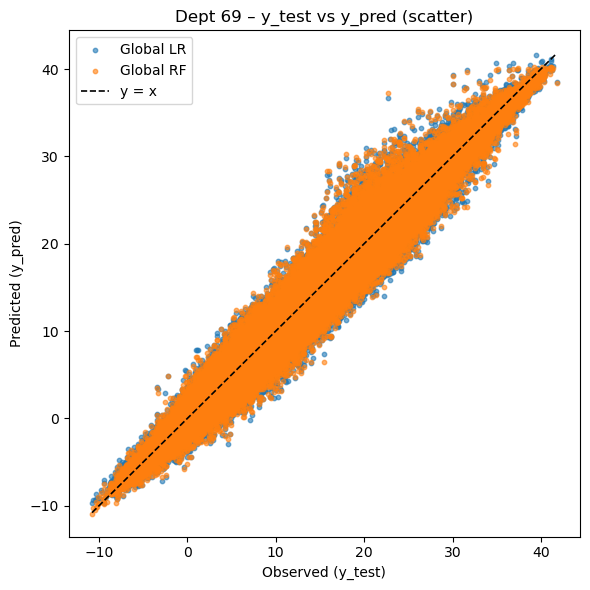

In [9]:
# Scatter plot y_test vs y_pred + ligne y = x
for d in dept_list:
    res = results[d]

    # y_test = valeurs réelles du jeu de test global
    y_test = res["y_test"].values

    # y_pred_lr = prédictions du modèle global LR
    y_pred_lr = res["y_pred_lr"]

    # y_pred_rf = prédictions du modèle global RF
    y_pred_rf = res["y_pred_rf"]

    # Limites pour tracer la ligne y=x (basée sur les valeurs réelles)
    lo, hi = float(np.min(y_test)), float(np.max(y_test))

    # Graphique de dispersion (scatter plot)
    plt.figure(figsize=(6, 6))

    # Points LR
    plt.scatter(y_test, y_pred_lr, s=10, alpha=0.6, label="Global LR")

    # Points RF
    plt.scatter(y_test, y_pred_rf, s=10, alpha=0.6, label="Global RF")

    # Ligne de référence y = x
    plt.plot([lo, hi], [lo, hi], "k--", linewidth=1.2, label="y = x")

    # Titre et axes
    plt.title(f"Dept {d} – y_test vs y_pred (scatter)")
    plt.xlabel("Observed (y_test)")
    plt.ylabel("Predicted (y_pred)")
    plt.legend()
    plt.tight_layout()
    plt.show()

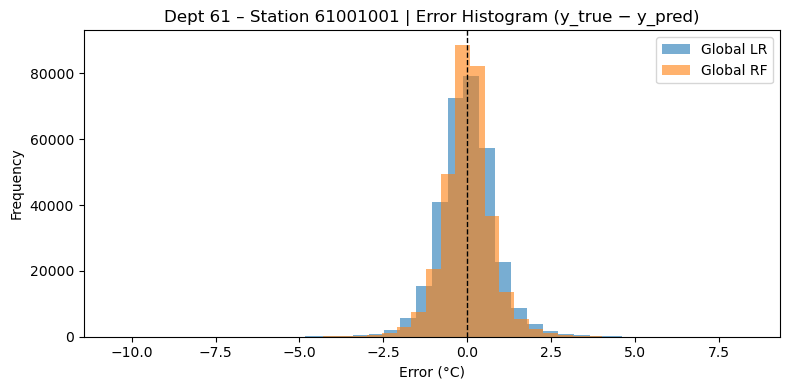

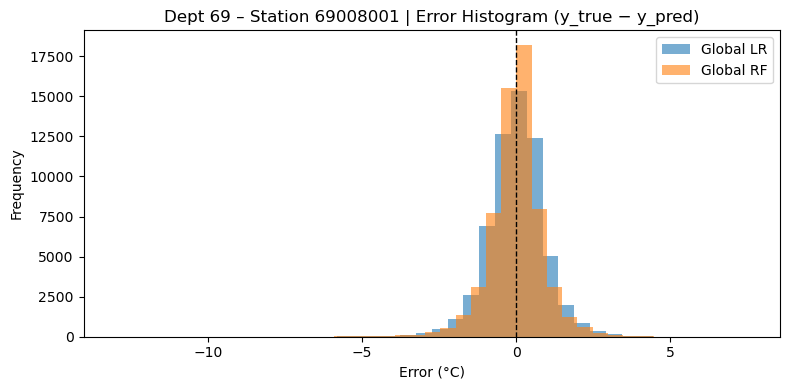

In [10]:
# Histogramme des erreurs pour analyser la distribution des écarts entre y_true et y_pred
for d in dept_list:
    res = results[d]

    # Stations triées numériquement
    stations_sorted = sorted(
        dept_fe[d]["station_id"].astype(str).str.strip().unique(),
        key=lambda x: (pd.to_numeric(''.join(filter(str.isdigit, x)), errors='coerce'), x)
    )
    st = stations_sorted[0]  

    # Extraction des données + scaling
    subset, num_cols, X_scaled, y_true = get_subset_scaled(d, st, res)

    # Prédictions des modèles globaux
    y_pred_lr = res["lr_model"].predict(X_scaled)
    y_pred_rf = res["rf_model"].predict(X_scaled)

    # Calcul des erreurs (observé - prédit)
    err_lr = y_true - y_pred_lr
    err_rf = y_true - y_pred_rf

    # Histogrammes des erreurs LR et RF
    plt.figure(figsize=(8, 4))
    plt.hist(err_lr, bins=40, alpha=0.6, label="Global LR")  
    plt.hist(err_rf, bins=40, alpha=0.6, label="Global RF")  

    plt.title(f"Dept {d} – Station {st} | Error Histogram (y_true − y_pred)")
    plt.axvline(0, color='black', linestyle='--', linewidth=1)

    plt.xlabel("Error (°C)")      
    plt.ylabel("Frequency")       
    plt.legend()
    plt.tight_layout()
    plt.show()

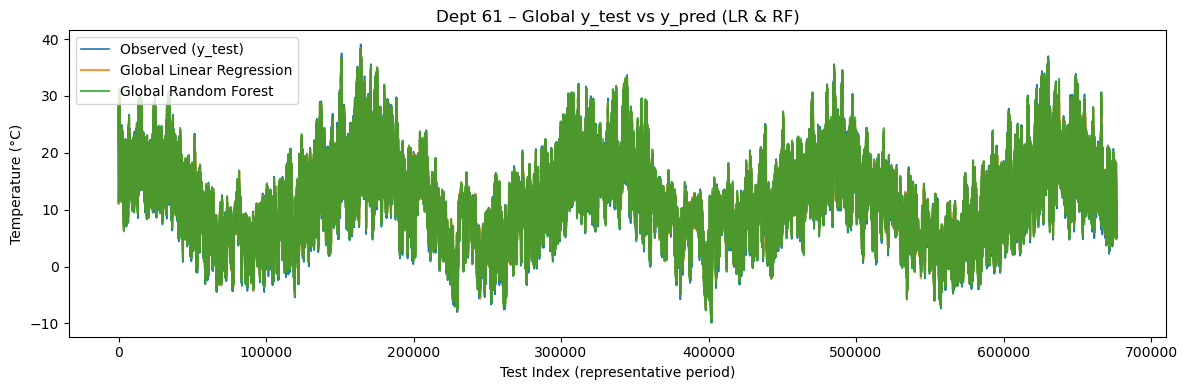

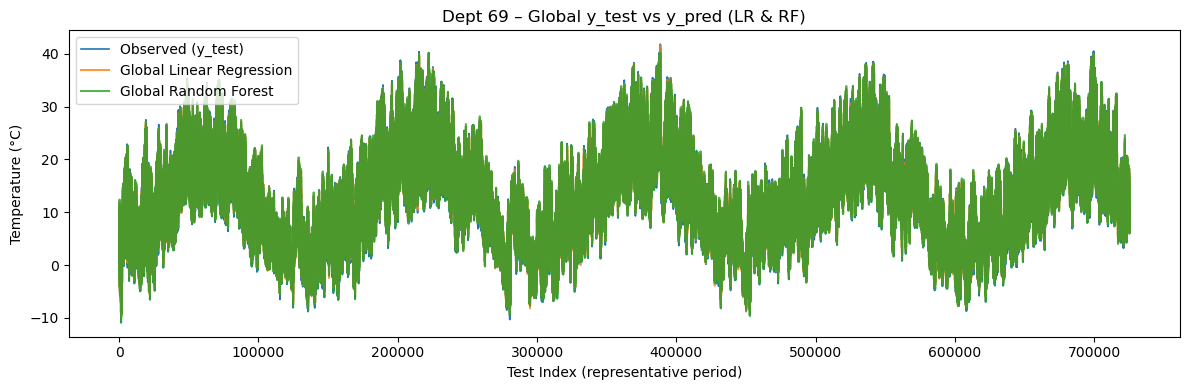

In [11]:
# Courbe y_test vs y_pred_global (LR & RF)
for d in dept_list:
    res = results[d]

    # y_test = valeurs réelles du jeu de test global
    y_test = res["y_test"].values

    # y_pred_lr = prédictions LR sur le test global
    y_pred_lr = res["y_pred_lr"]

    # y_pred_rf = prédictions RF sur le test global
    y_pred_rf = res["y_pred_rf"]

    # Courbe overlay
    plt.figure(figsize=(12, 4))

    # Série réelle (test global)
    plt.plot(y_test, label="Observed (y_test)", linewidth=1.2)

    # Global LR
    plt.plot(y_pred_lr, label="Global Linear Regression", alpha=0.8)

    # Global RF
    plt.plot(y_pred_rf, label="Global Random Forest", alpha=0.8)

    # Titres et axes
    plt.title(f"Dept {d} – Global y_test vs y_pred (LR & RF)")
    plt.xlabel("Test Index (representative period)")
    plt.ylabel("Temperature (°C)")
    plt.legend()
    plt.tight_layout()
    plt.show()

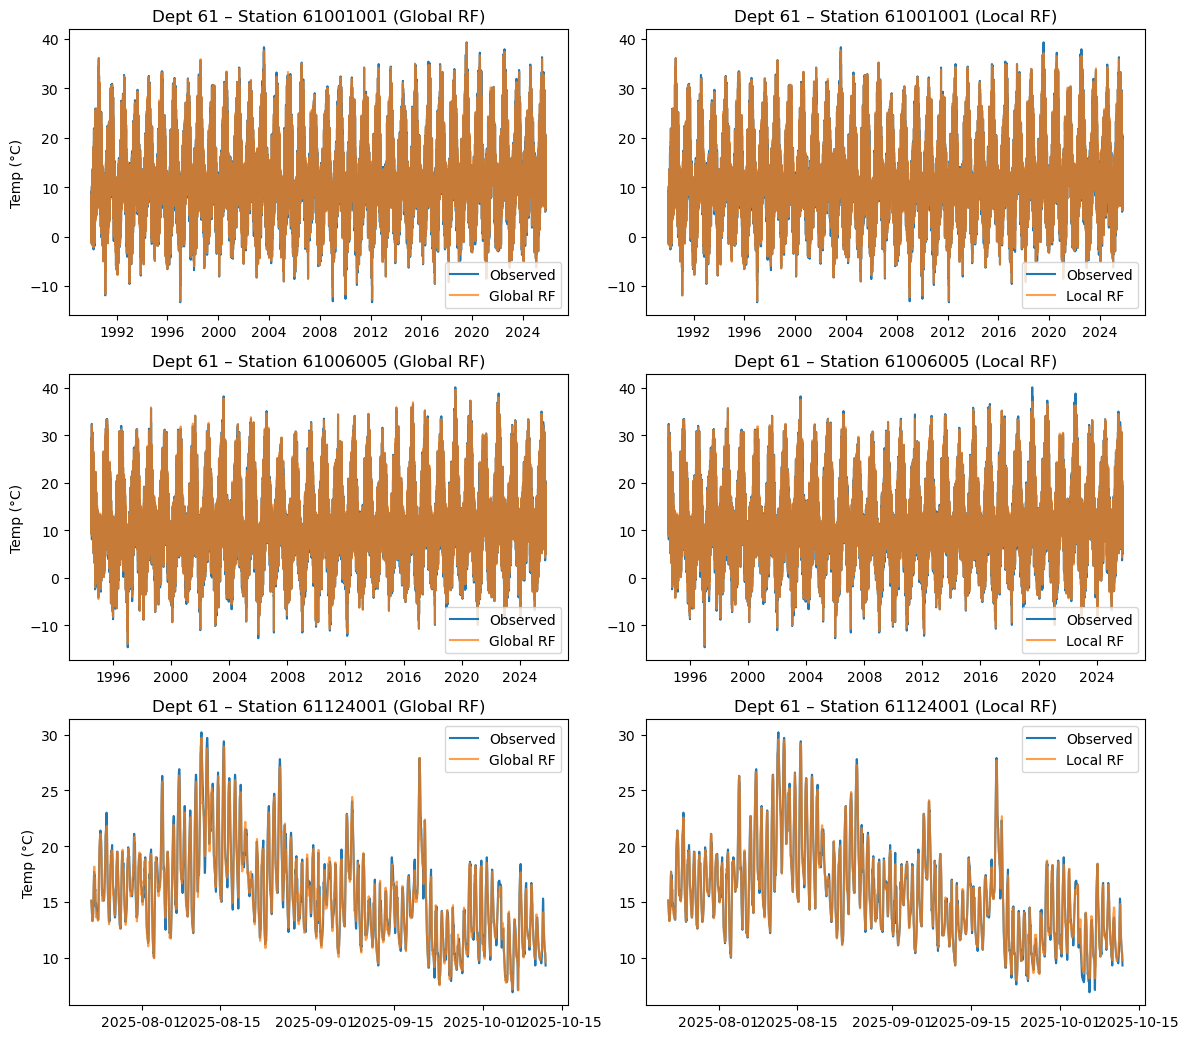

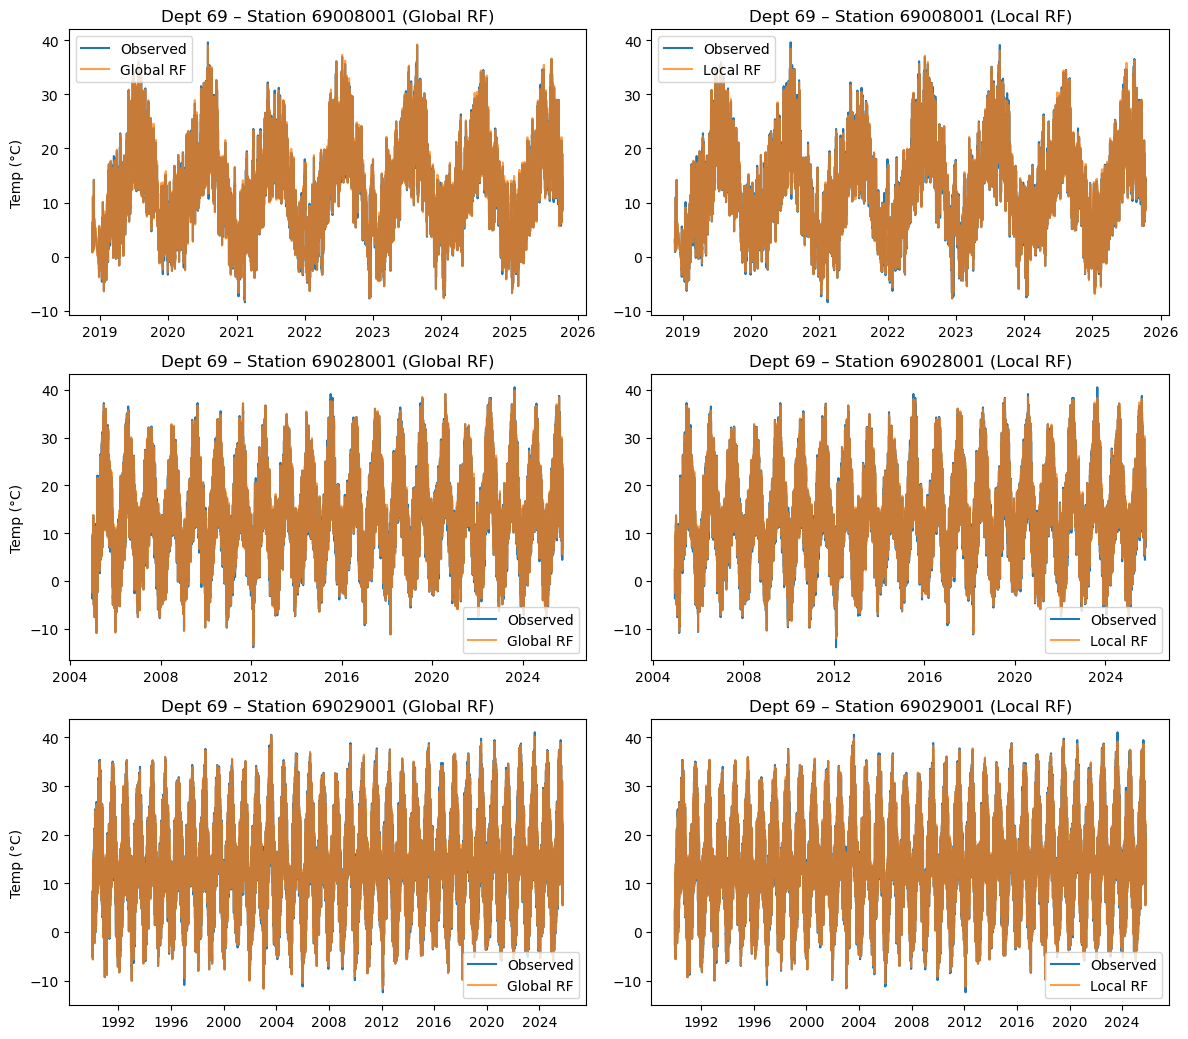

In [12]:
# Comparaison visuelle Global RF vs Local RF pour 3 stations représentatives
for d in dept_list:
    res = results[d]

    # Charger les métriques globales pour filtrer les stations valides
    global_metrics_path = f"results_per_station_global_model_DEPT_{d}.csv"
    global_metrics = pd.read_csv(global_metrics_path)

    # Stations avec métriques globales valides (pas NaN)
    valid_stations = global_metrics.dropna(
        subset=["mse_rf_global"]
    )["station_id"].astype(str).tolist()

    # Sélection des 3 premières stations valides (triées numériquement)
    stations_sorted = sorted(
        [st for st in valid_stations if st in dept_fe[d]["station_id"].astype(str).unique()],
        key=lambda x: (pd.to_numeric("".join(filter(str.isdigit, x)), errors="coerce"), x)
    )[:3]

    # Figure avec 2 colonnes : Global RF (gauche) et Local RF (droite)
    fig, axes = plt.subplots(
        len(stations_sorted),
        2,
        figsize=(12, 3.5 * len(stations_sorted)),
        sharex=False
    )

    if len(stations_sorted) == 1:
        axes = np.array([axes])  # Normalisation si une seule ligne

    for i, st in enumerate(stations_sorted):

        # Extraction des données + scaling global
        subset, num_cols, X_scaled, y_true = get_subset_scaled(d, st, res)
        y_pred_global_rf = res["rf_model"].predict(X_scaled)

        # Colonne de gauche : Modèle Global RF
        left_ax = axes[i, 0]
        left_ax.plot(subset["AAAAMMJJHH"], y_true, label="Observed")
        left_ax.plot(subset["AAAAMMJJHH"], y_pred_global_rf, label="Global RF", alpha=0.75)
        left_ax.set_title(f"Dept {d} – Station {st} (Global RF)")
        left_ax.set_ylabel("Temp (°C)")
        left_ax.legend()

        # Colonne de droite : Modèle Local RF
        right_ax = axes[i, 1]
        local_rf_path = os.path.join(f"DEPT_{d}_PKL", f"DEPT_{d}_STATION_{st}_RF.pkl")

        if os.path.exists(local_rf_path):
            local_model = joblib.load(local_rf_path)
            y_pred_local_rf = local_model.predict(subset[num_cols])

            right_ax.plot(subset["AAAAMMJJHH"], y_true, label="Observed")
            right_ax.plot(subset["AAAAMMJJHH"], y_pred_local_rf, label="Local RF", alpha=0.75)
            right_ax.set_title(f"Dept {d} – Station {st} (Local RF)")
            right_ax.legend()
        else:
            right_ax.set_title(f"Dept {d} – Station {st} (Local RF missing)")
            right_ax.text(0.5, 0.5, "Local RF model\nNOT FOUND", ha='center', va='center')
            right_ax.set_axis_off()

    plt.tight_layout()
    plt.show()

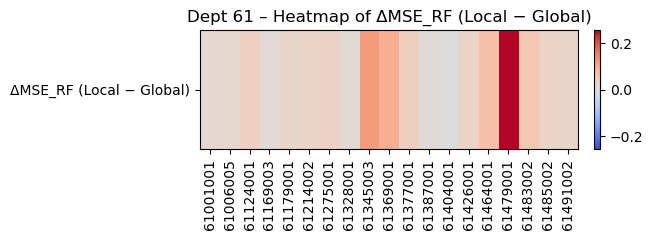

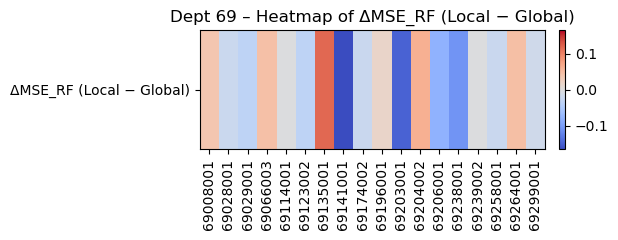

In [13]:
# Visualisation heatmap des différences de MSE entre modèles locaux et globaux (ΔMSE_RF)
for d in dept_list:
    comp_path = f"results_DEPT_{d}_TP02_vs_TP03.csv"

    # Vérification de l'existence du fichier comparatif
    if not os.path.exists(comp_path):
        print(f"Missing comparison file for dept {d}")
        continue

    # Lecture et préparation du tableau comparatif
    df = pd.read_csv(comp_path)
    df["station_id"] = df["station_id"].astype(str).str.strip()

    # Filtrer uniquement les stations avec valeurs valides
    df = df.dropna(subset=["mse_rf_local", "mse_rf_global"])

    # Tri des stations par numéro
    df["__num"] = pd.to_numeric(
        df["station_id"].str.extract(r"(\d+)", expand=False),
        errors="coerce"
    )
    df = df.sort_values(by=["__num", "station_id"]) \
           .drop(columns="__num") \
           .reset_index(drop=True)

    # Calcul des valeurs du heatmap : (Local – Global)
    vals = (df["mse_rf_local"] - df["mse_rf_global"]).values.reshape(1, -1)

    # Création de la figure du heatmap
    fig, ax = plt.subplots(1, 1, figsize=(0.35 * len(df), 2.5))

    # Matrice colorée
    im = ax.imshow(
        vals,
        aspect="auto",
        cmap="coolwarm",
        vmin=-np.nanmax(abs(vals)),
        vmax=np.nanmax(abs(vals))
    )

    # Axe Y : une seule ligne
    ax.set_yticks([0])
    ax.set_yticklabels(["ΔMSE_RF (Local − Global)"])

    # Axe X : ID des stations
    ax.set_xticks(range(len(df)))
    ax.set_xticklabels(df["station_id"].tolist(), rotation=90)

    # Titre et barre de couleurs
    plt.title(f"Dept {d} – Heatmap of ΔMSE_RF (Local − Global)")
    plt.colorbar(im, orientation="vertical", fraction=0.02, pad=0.04)

    plt.tight_layout()
    plt.show()